# Task 65: Custom Cross-Validation and Variance Analysis

Implement custom k-fold and stratified split mechanisms from scratch, guarantee balanced class representation across folds, and analyze variance in model performance across iterations and fold counts.


Total unique instances: 302, True positive class rate: 54.30%
=== FOLD-LEVEL VALIDATION: STRATIFIED K=5 ===
 Fold  Val_Size  Val_Pos_Pct  Accuracy  Precision   Recall       F1
    1        61    54.098361  0.885246   0.861111 0.939394 0.898551
    2        61    54.098361  0.901639   0.909091 0.909091 0.909091
    3        61    54.098361  0.770492   0.743590 0.878788 0.805556
    4        60    55.000000  0.800000   0.756098 0.939394 0.837838
    5        59    54.237288  0.813559   0.818182 0.843750 0.830769

=== FOLD-LEVEL VALIDATION: STANDARD (UNSTRATIFIED) K=5 ===
 Fold  Val_Size  Val_Pos_Pct  Accuracy  Precision   Recall       F1
    1        61    37.704918  0.852459   0.718750 1.000000 0.836364
    2        61    54.098361  0.803279   0.756098 0.939394 0.837838
    3        60    55.000000  0.833333   0.810811 0.909091 0.857143
    4        60    53.333333  0.800000   0.794118 0.843750 0.818182
    5        60    71.666667  0.816667   0.921053 0.813953 0.864198

=== VARIANCE & 

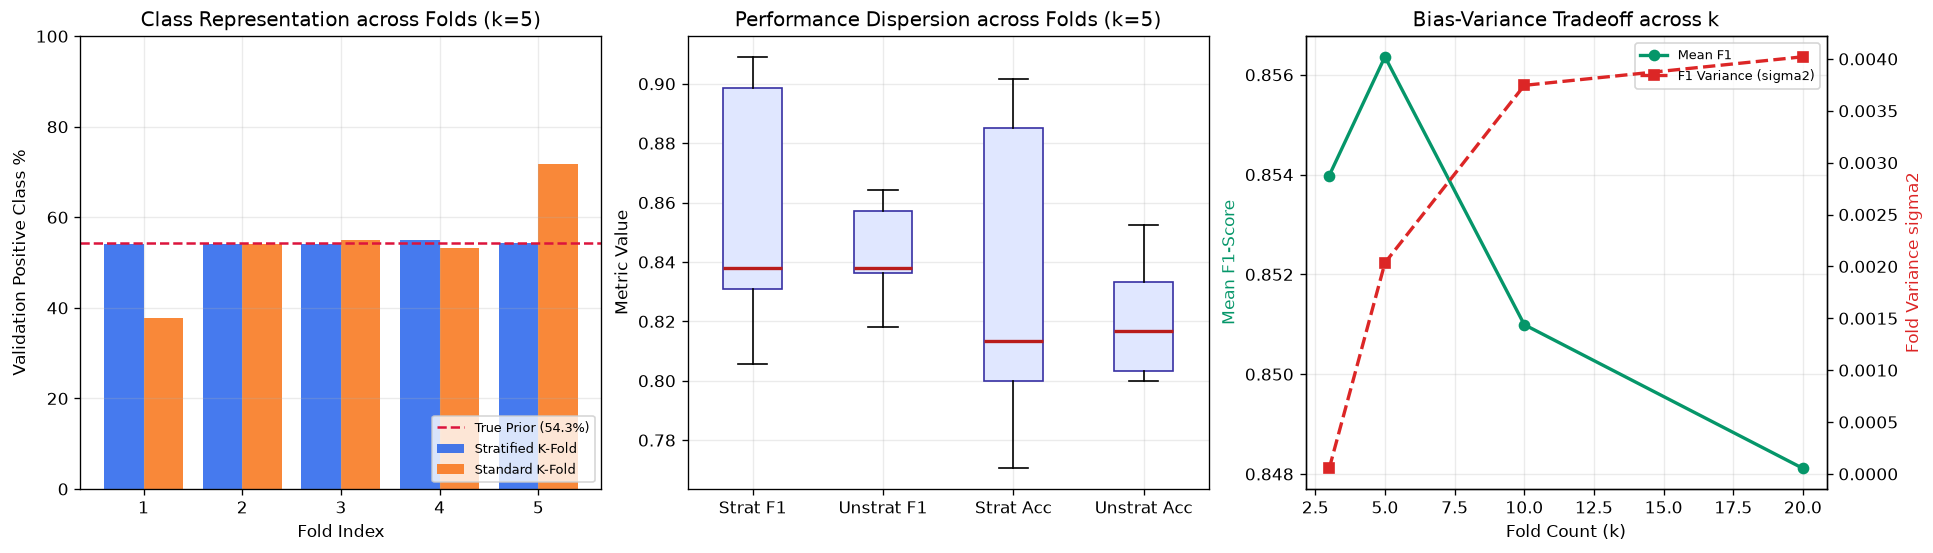

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths = [Path("heart.csv"), Path("Task_65_Custom_Cross_Validation_Variance_Analysis/heart.csv"), Path("Heart_Disease_Tasks/Task_65_Custom_Cross_Validation_Variance_Analysis/heart.csv")]
data = pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features = [c for c in ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal"] if c in data]
X, y = data[features].to_numpy(float), data["target"].to_numpy(int)
n_samples = len(y)
true_pos_pct = float(y.mean() * 100)
print(f"Total unique instances: {n_samples}, True positive class rate: {true_pos_pct:.2f}%")

def custom_kfold_split(n, k=5, shuffle=True, seed=42):
    rng = np.random.default_rng(seed)
    indices = rng.permutation(n) if shuffle else np.arange(n)
    folds = np.array_split(indices, k)
    splits = []
    all_idx = np.arange(n)
    for i in range(k):
        val_idx = folds[i]
        train_idx = np.setdiff1d(all_idx, val_idx)
        splits.append((train_idx, val_idx))
    return splits

def custom_stratified_kfold_split(y, k=5, shuffle=True, seed=42):
    rng = np.random.default_rng(seed)
    folds = [[] for _ in range(k)]
    for label in np.unique(y):
        cls_indices = np.flatnonzero(y == label)
        if shuffle:
            rng.shuffle(cls_indices)
        cls_folds = np.array_split(cls_indices, k)
        for i in range(k):
            folds[i].extend(cls_folds[i])
    splits = []
    all_idx = np.arange(len(y))
    for i in range(k):
        val_idx = np.array(folds[i], dtype=int)
        train_idx = np.setdiff1d(all_idx, val_idx)
        splits.append((train_idx, val_idx))
    return splits

class ScratchLogisticRegression:
    def fit(self, X, y, lr=0.06, iters=1200, l2=0.02):
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        n = len(y)
        for _ in range(iters):
            z = np.clip(X @ self.w + self.b, -35, 35)
            p = 1.0 / (1.0 + np.exp(-z))
            err = p - y
            self.w -= lr * ((X.T @ err) / n + l2 * self.w)
            self.b -= lr * err.mean()
        return self
    def predict(self, X):
        z = np.clip(X @ self.w + self.b, -35, 35)
        return (1.0 / (1.0 + np.exp(-z)) >= 0.5).astype(int)

def evaluate_splits(splits, X, y):
    records = []
    for fold_idx, (tr_idx, val_idx) in enumerate(splits, start=1):
        X_tr, X_va = X[tr_idx], X[val_idx]
        y_tr, y_va = y[tr_idx], y[val_idx]
        mu = X_tr.mean(axis=0)
        sd = np.where(X_tr.std(axis=0) == 0, 1.0, X_tr.std(axis=0))
        X_tr_s = (X_tr - mu) / sd
        X_va_s = (X_va - mu) / sd
        clf = ScratchLogisticRegression().fit(X_tr_s, y_tr)
        preds = clf.predict(X_va_s)
        tp = int(np.sum((y_va == 1) & (preds == 1)))
        tn = int(np.sum((y_va == 0) & (preds == 0)))
        fp = int(np.sum((y_va == 0) & (preds == 1)))
        fn = int(np.sum((y_va == 1) & (preds == 0)))
        prec = tp / (tp + fp) if (tp + fp) else 0.0
        rec = tp / (tp + fn) if (tp + fn) else 0.0
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
        acc = (tp + tn) / len(y_va)
        records.append({
            "Fold": fold_idx,
            "Val_Size": len(val_idx),
            "Val_Pos_Pct": float(y_va.mean() * 100),
            "Accuracy": acc,
            "Precision": prec,
            "Recall": rec,
            "F1": f1
        })
    return pd.DataFrame(records)

strat_5 = evaluate_splits(custom_stratified_kfold_split(y, k=5, seed=42), X, y)
unstrat_5 = evaluate_splits(custom_kfold_split(n_samples, k=5, seed=42), X, y)

print("=== FOLD-LEVEL VALIDATION: STRATIFIED K=5 ===")
print(strat_5.to_string(index=False))
print("\n=== FOLD-LEVEL VALIDATION: STANDARD (UNSTRATIFIED) K=5 ===")
print(unstrat_5.to_string(index=False))

def summarize_var(df, label):
    rows = []
    k = len(df)
    for col in ["Accuracy", "Precision", "Recall", "F1", "Val_Pos_Pct"]:
        v = df[col].to_numpy()
        m = float(np.mean(v))
        s2 = float(np.var(v, ddof=1))
        s = float(np.std(v, ddof=1))
        se = s / np.sqrt(k)
        rows.append({
            "Protocol": label,
            "Metric": col,
            "Mean": m,
            "Var (sigma2)": s2,
            "Std (sigma)": s,
            "SE": se,
            "95% CI Lower": m - 1.96 * se,
            "95% CI Upper": m + 1.96 * se,
            "Min": float(v.min()),
            "Max": float(v.max()),
            "Range": float(v.max() - v.min())
        })
    return pd.DataFrame(rows)

summary_table = pd.concat([summarize_var(strat_5, "Stratified K=5"), summarize_var(unstrat_5, "Standard K=5")], ignore_index=True)
print("\n=== VARIANCE & STABILITY ANALYSIS ACROSS ITERATIONS ===")
print(summary_table.to_string(index=False))

k_sweep = [3, 5, 10, 20]
sweep_records = []
for k_val in k_sweep:
    res = evaluate_splits(custom_stratified_kfold_split(y, k=k_val, seed=42), X, y)
    sweep_records.append({
        "k": k_val,
        "Train_Fraction": (k_val - 1) / k_val,
        "Mean_F1": res["F1"].mean(),
        "Var_F1": res["F1"].var(ddof=1),
        "Std_F1": res["F1"].std(ddof=1),
        "Mean_Acc": res["Accuracy"].mean(),
        "Var_Acc": res["Accuracy"].var(ddof=1)
    })
df_sweep = pd.DataFrame(sweep_records)
print("\n=== BIAS-VARIANCE SENSITIVITY ACROSS FOLD COUNTS (k) ===")
print(df_sweep.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
f_ids = strat_5["Fold"].to_numpy()
axes[0].bar(f_ids - 0.2, strat_5["Val_Pos_Pct"], width=0.4, label="Stratified K-Fold", color="#2563eb", alpha=0.85)
axes[0].bar(f_ids + 0.2, unstrat_5["Val_Pos_Pct"], width=0.4, label="Standard K-Fold", color="#f97316", alpha=0.85)
axes[0].axhline(true_pos_pct, color="crimson", linestyle="--", linewidth=1.5, label=f"True Prior ({true_pos_pct:.1f}%)")
axes[0].set_xlabel("Fold Index")
axes[0].set_ylabel("Validation Positive Class %")
axes[0].set_title("Class Representation across Folds (k=5)")
axes[0].set_ylim(0, 100)
axes[0].legend(loc="lower right", fontsize=8)
axes[0].grid(alpha=0.25)

box_data = [strat_5["F1"].to_numpy(), unstrat_5["F1"].to_numpy(), strat_5["Accuracy"].to_numpy(), unstrat_5["Accuracy"].to_numpy()]
axes[1].boxplot(box_data, tick_labels=["Strat F1", "Unstrat F1", "Strat Acc", "Unstrat Acc"], patch_artist=True,
                boxprops=dict(facecolor="#e0e7ff", color="#3730a3"), medianprops=dict(color="#b91c1c", linewidth=2))
axes[1].set_ylabel("Metric Value")
axes[1].set_title("Performance Dispersion across Folds (k=5)")
axes[1].grid(alpha=0.25)

ax_tw = axes[2].twinx()
l1 = axes[2].plot(df_sweep["k"], df_sweep["Mean_F1"], marker="o", color="#059669", linewidth=2, label="Mean F1")
l2 = ax_tw.plot(df_sweep["k"], df_sweep["Var_F1"], marker="s", color="#dc2626", linestyle="--", linewidth=2, label="F1 Variance (sigma2)")
axes[2].set_xlabel("Fold Count (k)")
axes[2].set_ylabel("Mean F1-Score", color="#059669")
ax_tw.set_ylabel("Fold Variance sigma2", color="#dc2626")
axes[2].set_title("Bias-Variance Tradeoff across k")
lines = l1 + l2
labels = [l.get_label() for l in lines]
axes[2].legend(lines, labels, loc="upper right", fontsize=8)
axes[2].grid(alpha=0.25)
plt.show()
